# S4 · MobileNet: spend computation where it matters
## Goal
Explain spatial filtering versus channel mixing, calculate convolution costs, implement a MobileNetV1 block, and recognize the MobileNetV2 inverted residual.

**CARN / DL · 19–20 October 2026.** Classroom companion; no additional graded homework. Core: V1; V2 is the bridge to next week's EfficientNet.

## Setup
Use the course `.venv` (Python + PyTorch + Matplotlib). CPU only, fixed seed, synthetic inputs; no downloads or pretrained weights. Saved outputs let you present without executing. Shapes use **N,C,H,W**.

In [1]:
import platform, time
from pathlib import Path
import torch
from torch import nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.benchmark import Timer
from IPython.display import display

torch.manual_seed(42)
torch.set_num_threads(1)
plt.rcParams.update({'font.size': 13, 'figure.dpi': 120,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, GREY = '#1768ac', '#c76319', '#46505d'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
print(f'Python {platform.python_version()} | PyTorch {torch.__version__} | CPU, 1 thread')

Python 3.13.5 | PyTorch 2.14.1 | CPU, 1 thread


## Steps
### 1 · What does a convolution pay for?
Imagine each input channel is a specialist's map. A standard convolution learns a different spatial filter for **every input–output channel pair**. A depthwise convolution gives each input channel its own spatial filter. A pointwise convolution mixes those filtered maps at each position.

The specialists are an analogy: deeper channels are learned features, not necessarily RGB.

For one image, no bias and no BatchNorm parameters:

| Operation | Weight shape in PyTorch | Parameters | MACs |
|---|---|---|---|
| Standard | `(Cout, Cin, k, k)` | `k² Cin Cout` | `Hout Wout k² Cin Cout` |
| Depthwise, multiplier 1 | `(Cin, 1, k, k)` | `k² Cin` | `Hout Wout k² Cin` |
| Pointwise | `(Cout, Cin, 1, 1)` | `Cin Cout` | `Hout Wout Cin Cout` |

**1 MAC = one multiply–accumulate** (often counted as 2 FLOPs). Biases, activations, normalization, memory traffic and batch size are excluded here. `Hout,Wout` matter, especially when stride is 2.

In [2]:
def costs(cin, cout, k, h, w):
    standard = k*k*cin*cout
    dw = k*k*cin
    pw = cin*cout
    return dict(standard=standard, depthwise=dw, pointwise=pw,
                separable=dw+pw, mac_standard=h*w*standard,
                mac_separable=h*w*(dw+pw))

example = costs(3, 8, 3, 5, 5)
assert example['standard'] == 216 and example['separable'] == 51
print('3 input channels → 8 output channels, 3×3 kernel, output 5×5')
print('Weights:', example['standard'], 'vs', example['separable'])
print('MACs:', example['mac_standard'], 'vs', example['mac_separable'])
print(f"Arithmetic reduction: {example['standard']/example['separable']:.2f}×; not a latency promise.")

3 input channels → 8 output channels, 3×3 kernel, output 5×5
Weights: 216 vs 51
MACs: 5400 vs 1275
Arithmetic reduction: 4.24×; not a latency promise.


### 2 · See what each channel does
We construct three **synthetic feature maps** and fixed filters for an inspectable example. The output at each location is a weighted sum across the depthwise maps. These are demonstration weights, not trained features.

Predict: if we change only channel 0, which depthwise output changes? Which pointwise outputs might change?

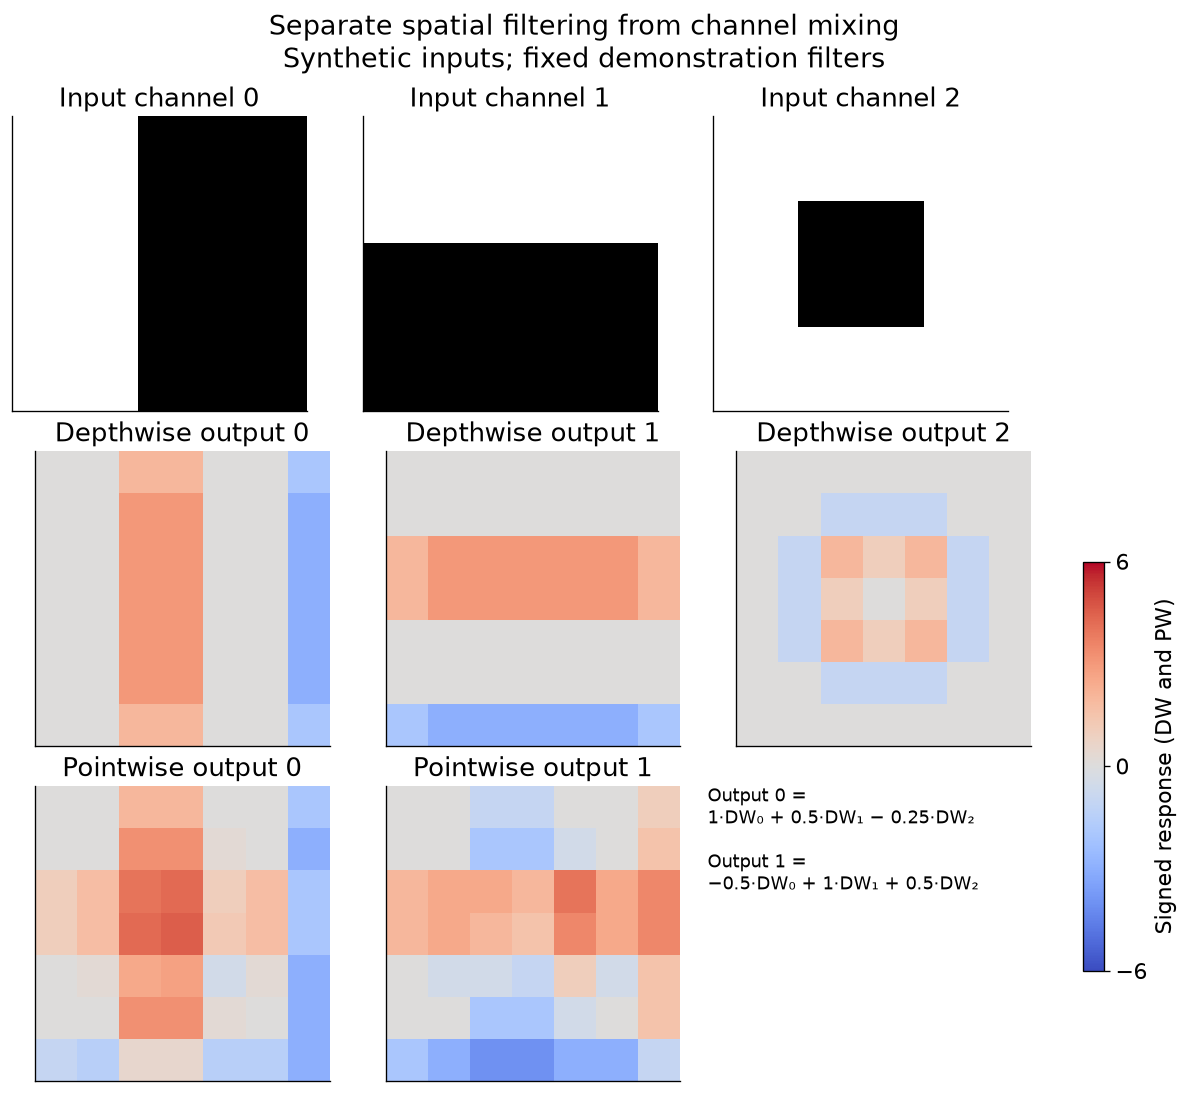

Check passed: changing input channel 0 leaves depthwise channels 1 and 2 unchanged.


In [3]:
maps = torch.zeros(1, 3, 7, 7)
maps[0, 0, :, 3:] = 1
maps[0, 1, 3:, :] = 1
maps[0, 2, 2:5, 2:5] = 1
filters = torch.tensor([
    [[-1.,0,1],[-1,0,1],[-1,0,1]],
    [[-1.,-1,-1],[0,0,0],[1,1,1]],
    [[0.,-1,0],[-1,4,-1],[0,-1,0]]
]).unsqueeze(1)
mix = torch.tensor([[1., 0.5, -0.25], [-0.5, 1., 0.5]])[:, :, None, None]
depth_maps = F.conv2d(maps, filters, padding=1, groups=3)
mixed_maps = F.conv2d(depth_maps, mix)
fig, axes = plt.subplots(3, 3, figsize=(10, 9), layout='constrained')
for c in range(3):
    axes[0,c].imshow(maps[0,c], vmin=0, vmax=1, cmap='Greys')
    axes[0,c].set_title(f'Input channel {c}')
    signed_image = axes[1,c].imshow(depth_maps[0,c], vmin=-6, vmax=6, cmap='coolwarm')
    axes[1,c].set_title(f'Depthwise output {c}')
for c in range(2):
    axes[2,c].imshow(mixed_maps[0,c], vmin=-6, vmax=6, cmap='coolwarm')
    axes[2,c].set_title(f'Pointwise output {c}')
axes[2,2].text(.05,.65, 'Output 0 =\n1·DW₀ + 0.5·DW₁ − 0.25·DW₂\n\nOutput 1 =\n−0.5·DW₀ + 1·DW₁ + 0.5·DW₂', fontsize=11)
for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([])
axes[2,2].set_frame_on(False)
fig.colorbar(signed_image, ax=axes[1:,:].ravel().tolist(), shrink=.65, label='Signed response (DW and PW)', ticks=[-6,0,6])
fig.suptitle('Separate spatial filtering from channel mixing\nSynthetic inputs; fixed demonstration filters', fontsize=16)
fig.savefig(FIG/'01_channel_flow.png'); plt.show()
changed = maps.clone(); changed[:,0] += 2
changed_depth = F.conv2d(changed, filters, padding=1, groups=3)
torch.testing.assert_close(changed_depth[:,1:], depth_maps[:,1:])
print('Check passed: changing input channel 0 leaves depthwise channels 1 and 2 unchanged.')

### 3 · Your turn: count before coding (6 minutes)
**A.** Input `(1,32,28,28)`, output channels 64, kernel 3, stride 1, padding 1, no biases.

1. Count standard, depthwise and pointwise weights.
2. Count MACs for the standard and separable layers.
3. What fraction of separable weights belongs to pointwise convolution?
4. If output resolution is halved in both dimensions, do parameter counts change?

Use [02_Playground.html](02_Playground.html) **after** students give their predictions. Select the 32→64 preset.

### 4 · Implement one V1 block
`groups=Cin` and `out_channels=Cin` give one spatial filter per input channel. `kernel_size=1` mixes channels. BatchNorm and ReLU follow **both** convolutions.

The full V1 network has a regular convolution stem, then depthwise-separable blocks, global average pooling and a classifier. It does **not** repeatedly alternate ordinary full convolutions with separable blocks.

In [4]:
class DepthwiseSeparable(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.depthwise = nn.Conv2d(cin, cin, 3, stride, padding=1, groups=cin, bias=False)
        self.pointwise = nn.Conv2d(cin, cout, 1, bias=False)
        self.bn1, self.bn2 = nn.BatchNorm2d(cin), nn.BatchNorm2d(cout)
        self.relu = nn.ReLU()
    def forward(self, x):
        x = self.relu(self.bn1(self.depthwise(x)))
        return self.relu(self.bn2(self.pointwise(x)))

block = DepthwiseSeparable(32,64).eval()
x = torch.randn(1,32,28,28)
with torch.inference_mode(): y = block(x)
conv_weights = block.depthwise.weight.numel() + block.pointwise.weight.numel()
print('Input → output:', tuple(x.shape), '→', tuple(y.shape))
print('Convolution weights:', conv_weights)
print('Trainable parameters including BN scale/offset:', sum(p.numel() for p in block.parameters()))
assert y.shape == (1,64,28,28) and conv_weights == 2336
assert sum(p.numel() for p in block.parameters()) == 2528
assert DepthwiseSeparable(32,64,stride=2).eval()(x).shape == (1,64,14,14)

Input → output: (1, 32, 28, 28) → (1, 64, 28, 28)
Convolution weights: 2336
Trainable parameters including BN scale/offset: 2528


### 5 · What do we lose by factorizing?
Fewer weights impose a constraint; separable convolution cannot represent every arbitrary standard convolution with multiplier 1.

**Optional mathematical check:** remove BN and activation. Compose `DW` and `PW` into a constrained standard kernel:
`W[out,in,:,:] = PW[out,in,0,0] * DW[in,0,:,:]`.
For a fixed input channel, every output uses a scaled copy of the same spatial filter. With nonlinearities inserted, this simple kernel composition no longer applies.

In [5]:
torch.manual_seed(7)
dw = nn.Conv2d(3,3,3,padding=1,groups=3,bias=False)
pw = nn.Conv2d(3,8,1,bias=False)
standard = nn.Conv2d(3,8,3,padding=1,bias=False)
with torch.no_grad():
    standard.weight.copy_(pw.weight[:,:,0,0][:,:,None,None] * dw.weight[:,0][None])
test = torch.randn(2,3,7,7)
with torch.inference_mode():
    error = (standard(test) - pw(dw(test))).abs().max().item()
torch.testing.assert_close(standard(test), pw(dw(test)), atol=1e-6, rtol=1e-5)
print(f'Constrained standard kernel = linear DW→PW pair. Max difference: {error:.2e}')

Constrained standard kernel = linear DW→PW pair. Max difference: 2.38e-07


### 6 · Two controls: width and resolution
For an idealized internal layer, width `α` scales **both** channel counts. Resolution `ρ` scales both output dimensions:

`P = k²(α Cin) + (α Cin)(α Cout)`  
`MACs = (ρ Hout)(ρ Wout) P`

The depthwise term scales linearly with α; the pointwise term quadratically. Resolution changes arithmetic and activations, not the number of convolution weights. Real implementations round channels to integers/divisibility constraints. Accuracy must be measured after training; this plot predicts only arithmetic.

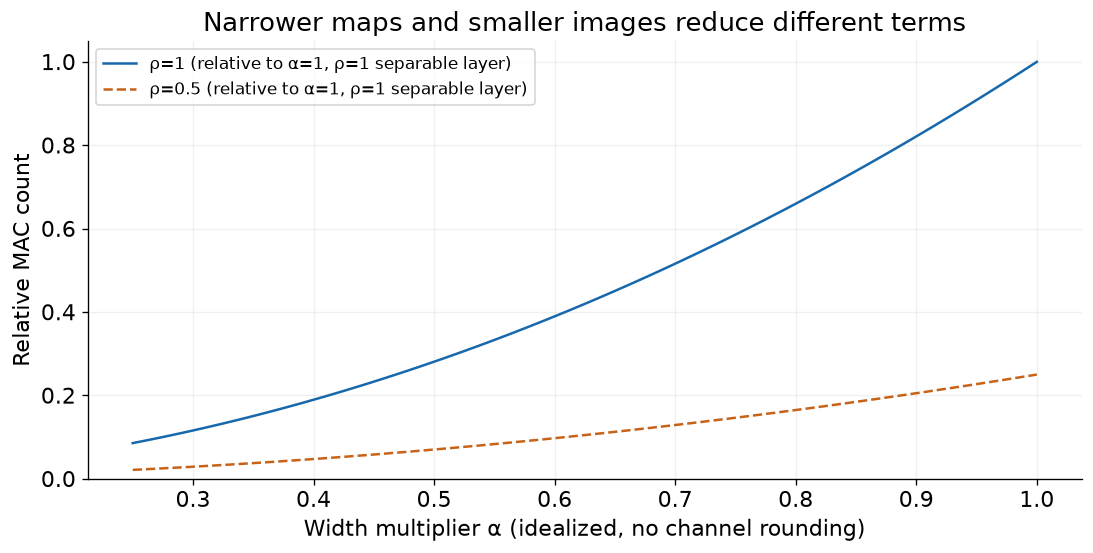

In [6]:
alphas = np.linspace(.25, 1., 80)
base = costs(32,64,3,28,28)
p = 9*(32*alphas) + (32*alphas)*(64*alphas)
fig, ax = plt.subplots(figsize=(9,4.5),layout='constrained')
for rho, color, style in [(1,BLUE,'-'),(.5,ORANGE,'--')]:
    ax.plot(alphas, rho*rho*p/base['separable'], color=color, linestyle=style,
            label=f'ρ={rho:g} (relative to α=1, ρ=1 separable layer)')
ax.set(xlabel='Width multiplier α (idealized, no channel rounding)',ylabel='Relative MAC count',
       title='Narrower maps and smaller images reduce different terms',ylim=(0,1.05))
ax.legend(fontsize=10); ax.grid(alpha=.18)
fig.savefig(FIG/'02_width_resolution.png'); plt.show()

### 7 · Arithmetic is not a stopwatch
Benchmark the two **convolution-only** alternatives on this CPU. Both receive the same tensor and produce the same output shape, but use independent random weights and are not functionally equivalent.

Use evaluation/inference mode, warm-up, one CPU thread and repeated timing. The result depends on shape, backend, hardware, batch size and memory layout. A mobile-device conclusion needs an on-device measurement. GPU/MPS timing requires appropriate synchronization.

In [7]:
bench_x = torch.randn(1,32,28,28)
bench_standard = nn.Conv2d(32,64,3,padding=1,bias=False).eval()
bench_separable = nn.Sequential(nn.Conv2d(32,32,3,padding=1,groups=32,bias=False),
                                nn.Conv2d(32,64,1,bias=False)).eval()
@torch.inference_mode()
def infer(model, tensor): return model(tensor)
measurements=[]
for label, model in [('Standard',bench_standard),('Depthwise + pointwise',bench_separable)]:
    for _ in range(20): infer(model,bench_x)
    t=Timer(stmt='infer(model, tensor)',globals={'infer':infer,'model':model,'tensor':bench_x},num_threads=1)
    m=t.blocked_autorange(min_run_time=.3)
    measurements.append(m)
    print(f'{label}: median {m.median*1e6:.1f} µs; IQR {m.iqr*1e6:.1f} µs; {len(m.raw_times)} timing blocks')
    if m.iqr / m.median > .1:
        print('  High variability (IQR > 10% of median): treat this run as illustrative, not a reliable speed estimate.')
print(f"Arithmetic ratio: {base['standard']/base['separable']:.2f}×")
print(f'Measured latency ratio on this run: {measurements[0].median/measurements[1].median:.2f}×')

Standard: median 97.0 µs; IQR 20.7 µs; 28 timing blocks
  High variability (IQR > 10% of median): treat this run as illustrative, not a reliable speed estimate.


Depthwise + pointwise: median 72.5 µs; IQR 3.9 µs; 5 timing blocks
Arithmetic ratio: 7.89×
Measured latency ratio on this run: 1.34×


### 8 · Why V2 expands before filtering
V2 uses **thin → wide → thin**: pointwise expansion → depthwise spatial filtering → linear pointwise projection. The final projection has BN but **no ReLU**. Add the input only if stride is 1 and input/output channels match.

Toy intuition: a scalar ReLU maps every negative value to 0. Encoding `x` as `(x,−x)` before ReLU allows reconstruction as `ReLU(x)−ReLU(−x)`. This demonstrates how extra channels *can* preserve information; it is not a proof that an arbitrary learned expansion does so.

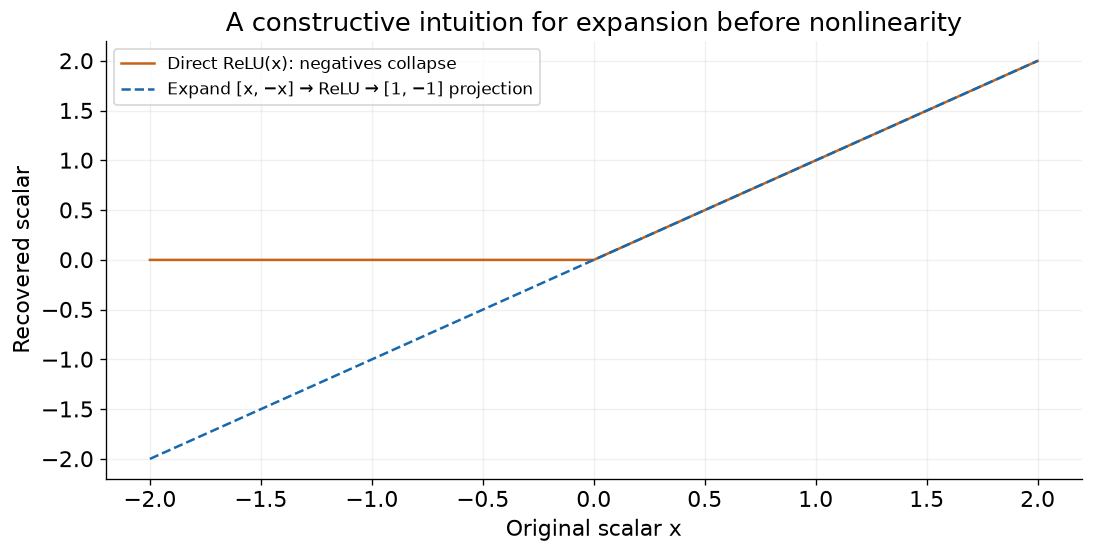

In [8]:
values = torch.linspace(-2,2,101)
encoded = torch.stack([values,-values],dim=1).relu()
reconstructed = encoded[:,0]-encoded[:,1]
torch.testing.assert_close(reconstructed,values)
fig, ax = plt.subplots(figsize=(9,4.5),layout='constrained')
ax.plot(values,values.relu(),color=ORANGE,label='Direct ReLU(x): negatives collapse')
ax.plot(values,reconstructed,color=BLUE,linestyle='--',label='Expand [x, −x] → ReLU → [1, −1] projection')
ax.set(xlabel='Original scalar x',ylabel='Recovered scalar',title='A constructive intuition for expansion before nonlinearity')
ax.legend(fontsize=10); ax.grid(alpha=.18)
fig.savefig(FIG/'03_linear_bottleneck.png'); plt.show()

In [9]:
class InvertedResidual(nn.Module):
    def __init__(self, cin, cout, stride=1, expansion=6):
        super().__init__()
        hidden = cin*expansion
        layers=[]
        if expansion != 1:
            layers += [nn.Conv2d(cin,hidden,1,bias=False),nn.BatchNorm2d(hidden),nn.ReLU6()]
        layers += [nn.Conv2d(hidden,hidden,3,stride,padding=1,groups=hidden,bias=False),
                   nn.BatchNorm2d(hidden),nn.ReLU6(),
                   nn.Conv2d(hidden,cout,1,bias=False),nn.BatchNorm2d(cout)]
        self.layers=nn.Sequential(*layers)
        self.use_residual = stride == 1 and cin == cout
    def forward(self,x):
        y=self.layers(x)
        return x+y if self.use_residual else y

for cin,cout,stride in [(16,16,1),(16,24,2),(16,24,1)]:
    model=InvertedResidual(cin,cout,stride).eval()
    output=model(torch.randn(1,cin,28,28))
    print(f'{cin} → {cout}, stride={stride}: {tuple(output.shape)}, skip={model.use_residual}')
    assert model.use_residual == (stride==1 and cin==cout)
# A zero residual branch must leave the input unchanged.
model=InvertedResidual(16,16).eval()
with torch.no_grad():
    for parameter in model.parameters(): parameter.zero_()
probe=torch.randn(1,16,8,8)
torch.testing.assert_close(model(probe),probe)
print('Residual identity check passed.')

16 → 16, stride=1: (1, 16, 28, 28), skip=True
16 → 24, stride=2: (1, 24, 14, 14), skip=False
16 → 24, stride=1: (1, 24, 28, 28), skip=False
Residual identity check passed.


### 9 · Inspect a real implementation (no download)
This is an untrained torchvision MobileNetV2. Use it to inspect shapes and the classifier; do not show its random predictions as meaningful recognition.

In [10]:
from torchvision.models import mobilenet_v2
real_model = mobilenet_v2(weights=None).eval()
with torch.inference_mode(): logits=real_model(torch.zeros(1,3,224,224))
print('Output shape:',tuple(logits.shape))
print('Parameters:',format(sum(p.numel() for p in real_model.parameters()),','))
print('First inverted residual block:')
print(real_model.features[1])
assert logits.shape == (1,1000)

Output shape: (1, 1000)
Parameters: 3,504,872
First inverted residual block:
InvertedResidual(
  (conv): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
)


## Checks
**B · Shape exercise (4 minutes):** a V2 block receives `(1,16,28,28)`, expansion 6, output channels 24, stride 2. Write the three output shapes. Is a skip valid? Where must ReLU be absent?

**C · Debug exercise (5 minutes):** a student writes `Conv2d(32,64,3,groups=32)` and claims it is the entire depthwise-separable block. Explain what it actually computes and add the missing operation. Then explain why `groups=1` would be different.

**Exit ticket:**
1. Which operation mixes channels?
2. Which operation visits neighbouring spatial positions?
3. Does doubling image width double parameter count?
4. Does 8× fewer MACs guarantee 8× lower latency?
5. Can every full convolution be represented by multiplier-1 DW→PW without changing the function?

## Next Steps
EfficientNet builds on efficient blocks and model scaling; its full treatment belongs to S5. No new assignment or deadline is introduced here.

Primary sources: [MobileNetV1](https://arxiv.org/abs/1704.04861), [MobileNetV2](https://arxiv.org/abs/1801.04381), [PyTorch Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [torchvision MobileNetV2](https://docs.pytorch.org/vision/stable/models/mobilenetv2.html).